# LAB 08 — Support Vector Machines
## Student Information
- **Name:** Abdul Moiz
- **Student ID:** 023-24-0291
- **Section:** H
- **GitHub:** https://github.com/abdulmoizsoomrocs/ML_LAB_8.git
- **Kaggle:** (https://www.kaggle.com/abdulmoizsoomro)
- **Dataset:** clean_churn
- **Dataset Source:** from lab3


## Part 0 — Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

In [2]:
# Read the CSV file
df = pd.read_csv("clean_churn.csv")

# Remove customerID if it exists
if "customerID" in df.columns:
    df = df.drop("customerID", axis=1)

# Make TotalCharges numeric if that column exists
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

# Change Churn from Yes/No to 1/0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0}).fillna(df["Churn"]).astype(int)

print("Rows and columns:", df.shape)
print("Missing values:", df.isnull().sum().sum())
df.head()

Rows and columns: (7032, 20)
Missing values: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


### Prepare the data

Machine learning needs numbers. We turn text columns into number columns using `get_dummies()`. We split the data into training data (to teach the model) and test data (to check it).

In [3]:
# Separate the answer column from the other columns
X = df.drop("Churn", axis=1)
y = df["Churn"]

# Turn text columns into number columns
X = pd.get_dummies(X, drop_first=False)

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Number of features:", X_train.shape[1])

Training rows: 5625
Testing rows: 1407
Number of features: 45


In [4]:
# Scale the data for SVM.
# Learn the scaling values from training data only.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data is ready.")

Data is ready.


## Part 1 — Why does scaling matter?

We train one SVM without scaling and one with scaling. We compare accuracy, F1-score, and training time.

In [5]:
results = []

# Model 1: no scaling
start = time.time()
svm_unscaled = SVC(kernel="linear", random_state=42)
svm_unscaled.fit(X_train, y_train)
time_unscaled = time.time() - start
pred_unscaled = svm_unscaled.predict(X_test)

results.append([
    "Without scaling",
    accuracy_score(y_test, pred_unscaled),
    f1_score(y_test, pred_unscaled),
    time_unscaled
])

# Model 2: scaled data
start = time.time()
svm_scaled = SVC(kernel="linear", random_state=42)
svm_scaled.fit(X_train_scaled, y_train)
time_scaled = time.time() - start
pred_scaled = svm_scaled.predict(X_test_scaled)

results.append([
    "With scaling",
    accuracy_score(y_test, pred_scaled),
    f1_score(y_test, pred_scaled),
    time_scaled
])

part1 = pd.DataFrame(
    results, columns=["Model", "Accuracy", "F1-score", "Training time (seconds)"]
)
part1

,Model,Accuracy,F1-score,Training time (seconds)
0,Without scaling,0.783937,0.522013,573.525780
1,With scaling,0.798863,0.593974,2.246865


**Answer in simple words**

- **(a)** Look at the table above. Compare the accuracy, F1-score, and training time for the two rows.
- **(b)** SVM uses distances to create its boundary. Large-number columns can dominate small-number columns. Scaling makes feature ranges more comparable.
- **(c)** We use scaled data for the next SVM tasks because SVM is affected by feature scale.

## Part 2 — Compare three kernels

A kernel is a way for SVM to learn a boundary. We compare `linear`, `rbf`, and `poly` using the same training and test data.

In [19]:
kernel_results = []
kernel_predictions = {}
kernel_models = {}

for kernel_name in ["linear", "rbf", "poly"]:
    model = SVC(kernel=kernel_name, random_state=42)
    model.fit(X_train_scaled, y_train)
    prediction = model.predict(X_test_scaled)

    kernel_models[kernel_name] = model
    kernel_predictions[kernel_name] = prediction

    kernel_results.append([
        kernel_name,
        accuracy_score(y_test, prediction),
        precision_score(y_test, prediction, zero_division=0),
        recall_score(y_test, prediction, zero_division=0),
        f1_score(y_test, prediction, zero_division=0),
        len(model.support_)
    ])

kernel_table = pd.DataFrame(
    kernel_results,
    columns=["Kernel", "Accuracy", "Precision", "Recall", "F1-score", "Support vectors"]
)
kernel_table.sort_values("F1-score", ascending=False)

,Kernel,Accuracy,Precision,Recall,F1-score,Support vectors
0,linear,0.798863,0.640867,0.553476,0.593974,2568
1,rbf,0.788913,0.625407,0.513369,0.563877,2699
2,poly,0.782516,0.614094,0.489305,0.544643,2746


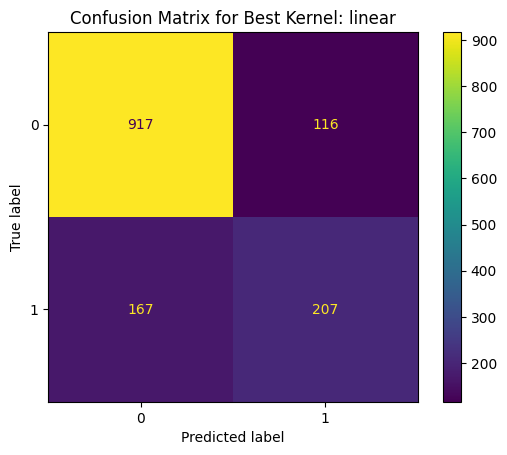

Best kernel by F1-score: linear


In [7]:
# Pick the kernel with the highest F1-score
best_kernel = kernel_table.sort_values("F1-score", ascending=False).iloc[0]["Kernel"]
ConfusionMatrixDisplay.from_predictions(y_test, kernel_predictions[best_kernel])
plt.title("Confusion Matrix for Best Kernel: " + best_kernel)
plt.show()
print("Best kernel by F1-score:", best_kernel)

**Answer in simple words**

- **(a)** The kernel with the highest F1-score in the table is the best one for this test.
- **(b)** The support-vector column shows how many training examples help define each boundary. A high count does not automatically mean overfitting.
- **(c)** Use the measured results to discuss the best kernel. The next part of the manual specifically tunes an RBF SVM.

## Part 3 — What does C do?

PCA makes a two-dimensional version of the data so we can draw it. The plot is only a simplified view of the original data.

In [8]:
pca = PCA(n_components=2, random_state=42)
X_train_2d = pca.fit_transform(X_train_scaled)
print("Information shown by the two PCA components:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

Information shown by the two PCA components: 38.61 %


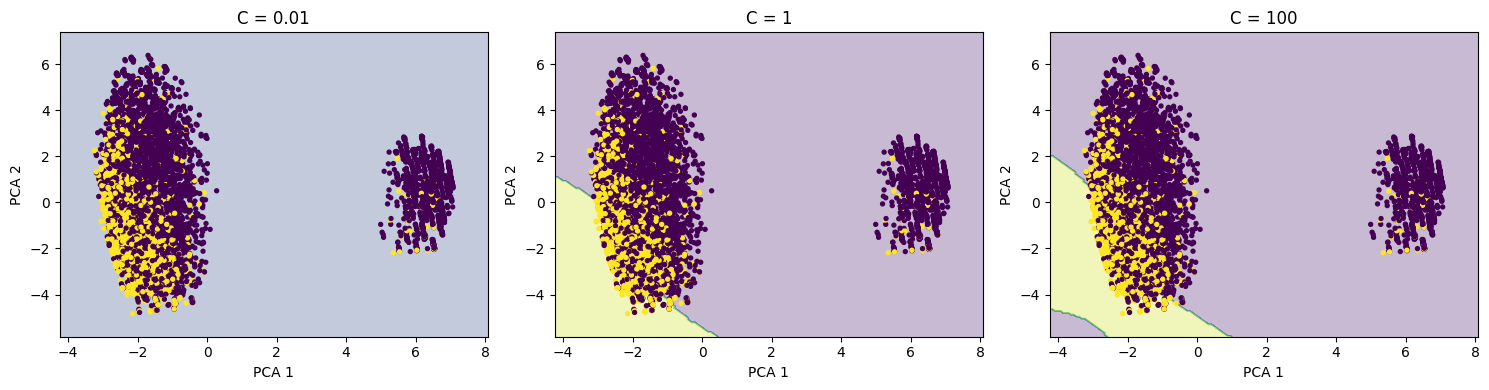

,C,Support vectors
0,0.01,3001
1,1.00,2699
2,100.00,2645


In [9]:
# Draw decision boundaries for small, medium, and large C
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 160),
    np.linspace(y_min, y_max, 160)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
C_values = [0.01, 1, 100]
support_counts = []

for ax, c_value in zip(axes, C_values):
    model = SVC(kernel="rbf", C=c_value, random_state=42)
    model.fit(X_train_2d, y_train)

    grid = np.c_[xx.ravel(), yy.ravel()]
    predicted_grid = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, predicted_grid, alpha=0.3)
    ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, s=8)
    ax.set_title("C = " + str(c_value))
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")
    support_counts.append([c_value, len(model.support_)])

plt.tight_layout()
plt.show()

pd.DataFrame(support_counts, columns=["C", "Support vectors"])

**Answer in simple words**

- **(a)** Compare how the boundary changes across the three plots. Larger C penalizes mistakes more strongly, so it may fit training data more closely.
- **(b)** Use the support-vector counts shown by the table. The count can change depending on the data.
- **(c)** A very simple boundary may underfit; a very complicated boundary may overfit. This plot is only a clue, not proof.
- **(d)** PCA keeps only two dimensions, so information is lost. The plotted model is trained on the two-dimensional data, not the full data.

## Part 4 — Find better C and gamma values

GridSearchCV tests several combinations and uses cross-validation to choose the one with the best average F1-score.

In [10]:
parameter_grid = {
    "C": [0.1, 1, 10],
    "gamma": [0.001, 0.01, 0.1]
}

search = GridSearchCV(
    SVC(kernel="rbf", random_state=42),
    parameter_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

start = time.time()
search.fit(X_train_scaled, y_train)
print("Search time in seconds:", round(time.time() - start, 2))
print("Best settings:", search.best_params_)
print("Best cross-validation F1-score:", round(search.best_score_, 4))

Search time in seconds: 93.5
Best settings: {'C': 10, 'gamma': 0.001}
Best cross-validation F1-score: 0.5846


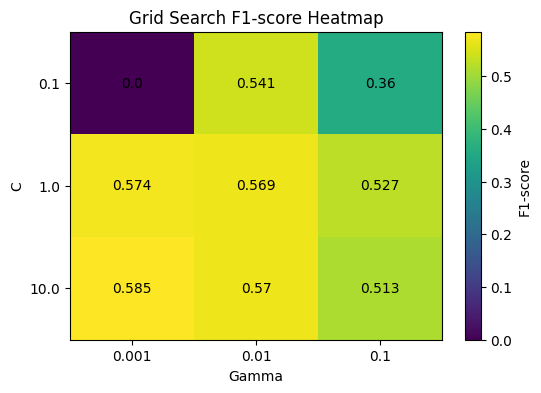

In [11]:
# Draw the score heatmap
cv_table = pd.DataFrame(search.cv_results_)
heatmap_data = cv_table.pivot(
    index="param_C", columns="param_gamma", values="mean_test_score"
)

plt.figure(figsize=(6, 4))
plt.imshow(heatmap_data, aspect="auto")
plt.xticks(range(len(heatmap_data.columns)), heatmap_data.columns)
plt.yticks(range(len(heatmap_data.index)), heatmap_data.index)
plt.xlabel("Gamma")
plt.ylabel("C")
plt.title("Grid Search F1-score Heatmap")
plt.colorbar(label="F1-score")
for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        plt.text(j, i, round(heatmap_data.iloc[i, j], 3),
                 ha="center", va="center")
plt.show()

Test accuracy: 0.7925
Test precision: 0.634
Test recall: 0.5187
Test F1-score: 0.5706
Confusion matrix:
[[921 112]
 [180 194]]


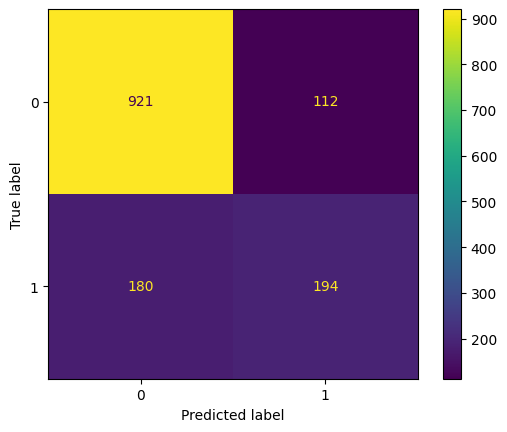

In [12]:
best_svm = search.best_estimator_
best_svm_prediction = best_svm.predict(X_test_scaled)

print("Test accuracy:", round(accuracy_score(y_test, best_svm_prediction), 4))
print("Test precision:", round(precision_score(y_test, best_svm_prediction, zero_division=0), 4))
print("Test recall:", round(recall_score(y_test, best_svm_prediction, zero_division=0), 4))
print("Test F1-score:", round(f1_score(y_test, best_svm_prediction, zero_division=0), 4))
print("Confusion matrix:")
print(confusion_matrix(y_test, best_svm_prediction))
ConfusionMatrixDisplay.from_predictions(y_test, best_svm_prediction)
plt.show()

**Answer in simple words**

- **(a)** The best C, gamma, and cross-validation F1-score are printed above.
- **(b)** In the heatmap, look for the highest score. Similar scores in nearby cells mean several settings work similarly.
- **(c)** Compare the cross-validation F1-score with the test F1-score. A large difference may mean the model does not generalize as well.
- **(d)** Compare the tuned RBF F1-score with the RBF F1-score from Part 2.

In [13]:
untuned_rbf_prediction = kernel_predictions["rbf"]
print("Untuned RBF test F1:",
      round(f1_score(y_test, untuned_rbf_prediction, zero_division=0), 4))
print("Tuned RBF test F1:",
      round(f1_score(y_test, best_svm_prediction, zero_division=0), 4))

Untuned RBF test F1: 0.5639
Tuned RBF test F1: 0.5706


## Part 5 — Handle class imbalance

Churners are fewer than customers who stay. `class_weight="balanced"` tells the model to pay more attention to the smaller class.

In [14]:
balance_results = []
balance_models = {}
balance_predictions = {}

for label, weight in [("Default", None), ("Balanced", "balanced")]:
    model = SVC(
        kernel="rbf",
        C=search.best_params_["C"],
        gamma=search.best_params_["gamma"],
        class_weight=weight,
        probability=True,
        random_state=42
    )
    model.fit(X_train_scaled, y_train)
    prediction = model.predict(X_test_scaled)

    balance_models[label] = model
    balance_predictions[label] = prediction
    balance_results.append([
        label,
        precision_score(y_test, prediction, zero_division=0),
        recall_score(y_test, prediction, zero_division=0),
        f1_score(y_test, prediction, zero_division=0)
    ])

balance_table = pd.DataFrame(
    balance_results, columns=["Model", "Precision", "Recall", "F1-score"]
)
display(balance_table)

for label, prediction in balance_predictions.items():
    print(label, "confusion matrix:")
    print(confusion_matrix(y_test, prediction))

,Model,Precision,Recall,F1-score
0,Default,0.633987,0.518717,0.570588
1,Balanced,0.450517,0.815508,0.580400


Default confusion matrix:
[[921 112]
 [180 194]]
Balanced confusion matrix:
[[661 372]
 [ 69 305]]


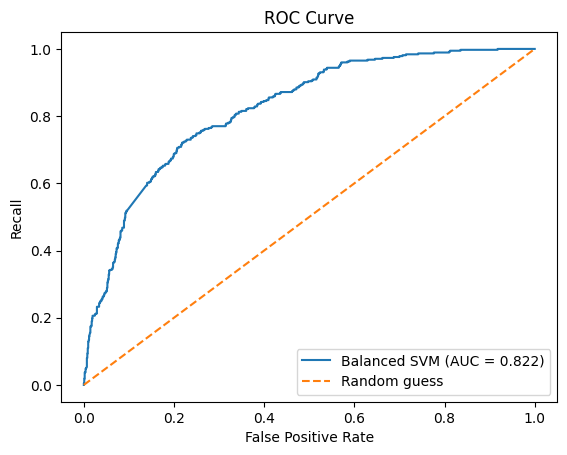

ROC AUC: 0.8224


In [15]:
# ROC curve for the balanced model
balanced_model = balance_models["Balanced"]
probabilities = balanced_model.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, probabilities)
auc_value = roc_auc_score(y_test, probabilities)

plt.plot(fpr, tpr, label="Balanced SVM (AUC = " + str(round(auc_value, 3)) + ")")
plt.plot([0, 1], [0, 1], "--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("Recall")
plt.title("ROC Curve")
plt.legend()
plt.show()
print("ROC AUC:", round(auc_value, 4))

**Answer in simple words**

- **(a)** Compare precision and recall in the table above.
- **(b)** A false negative means a customer who will churn was missed. A false positive means a customer was flagged but would stay. Choose the model based on which mistake is more costly.
- **(c)** We enabled `probability=True` in `SVC()` and used `predict_proba()` to get probability estimates for the ROC curve.

## Part 6 — Compare five models

We test five algorithms using the same split. The table and bar chart show their results.

In [16]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Tuned SVM": best_svm
}

comparison = []
predictions_by_model = {}

for name, model in models.items():
    if name != "Tuned SVM":
        model.fit(X_train_scaled, y_train)
    prediction = model.predict(X_test_scaled)
    predictions_by_model[name] = prediction
    comparison.append([
        name,
        accuracy_score(y_test, prediction),
        precision_score(y_test, prediction, zero_division=0),
        recall_score(y_test, prediction, zero_division=0),
        f1_score(y_test, prediction, zero_division=0)
    ])

comparison_table = pd.DataFrame(
    comparison,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1-score"]
).sort_values("F1-score", ascending=False)

display(comparison_table)

,Model,Accuracy,Precision,Recall,F1-score
2,Logistic Regression,0.803838,0.647590,0.574866,0.609065
4,Tuned SVM,0.792466,0.633987,0.518717,0.570588
1,Random Forest,0.787491,0.630662,0.483957,0.547655
3,KNN,0.739872,0.510050,0.542781,0.525907
0,Decision Tree,0.730633,0.493369,0.497326,0.495340


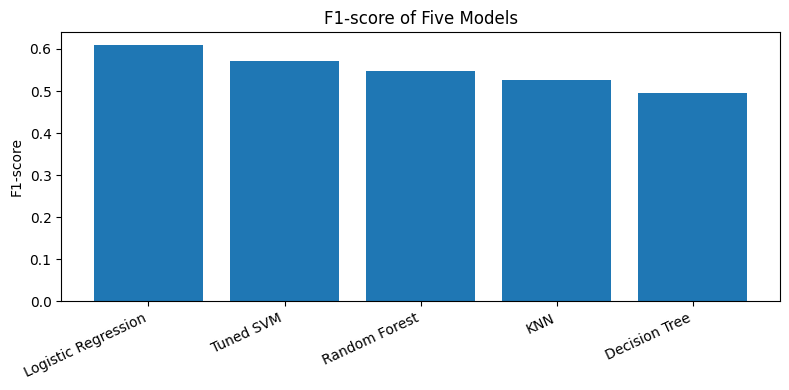

Best F1 model: Logistic Regression
Best recall model: Logistic Regression


In [17]:
plt.figure(figsize=(8, 4))
plt.bar(comparison_table["Model"], comparison_table["F1-score"])
plt.ylabel("F1-score")
plt.title("F1-score of Five Models")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

print("Best F1 model:", comparison_table.iloc[0]["Model"])
print("Best recall model:",
      comparison_table.loc[comparison_table["Recall"].idxmax(), "Model"])

**Answer in simple words**

- **(a)** The best F1 and recall models are printed above. Check whether they are the same.
- **(b)** SVM tuning takes extra time. Decide whether it is worth it by comparing its metrics with the tree models.
- **(c)** Recommend one model and mention at least two metrics, such as recall and F1-score. If missing churners is costly, recall is especially important.

## Part 7 — Save final predictions

We select the model with the highest F1-score from Part 6 and save its predictions to `svm_predictions.csv`.

In [18]:
final_model_name = comparison_table.iloc[0]["Model"]
final_model = models[final_model_name]
final_prediction = predictions_by_model[final_model_name]

if hasattr(final_model, "predict_proba"):
    final_score = final_model.predict_proba(X_test_scaled)[:, 1]
    score_name = "predicted churn probability"
else:
    final_score = final_model.decision_function(X_test_scaled)
    score_name = "decision score (not probability)"

output = pd.DataFrame({
    "true_churn": y_test.to_numpy(),
    "predicted_churn": final_prediction,
    "churn_probability_or_score": final_score
})
output.to_csv("svm_predictions.csv", index=False)

print("Saved svm_predictions.csv")
print("Chosen model:", final_model_name)
print("Score column:", score_name)
display(output.head())

Saved svm_predictions.csv
Chosen model: Logistic Regression
Score column: predicted churn probability


,true_churn,predicted_churn,churn_probability_or_score
0,0,0,0.017119
1,0,1,0.595996
2,0,0,0.004762
3,1,0,0.200133
4,0,0,0.100146


## Executive Summary

In this lab, I compared different SVM kernels and machine learning models for customer churn prediction. Logistic Regression achieved the best results among the five models, with 80.38% accuracy, 64.76% precision, 57.49% recall, and a 60.91% F1-score. I compared linear, RBF, and polynomial SVM kernels and used GridSearchCV to tune the RBF model. I also tested balanced class weights to understand their effect on precision and recall. Missing customers who are likely to churn can be costly for a telecom company, so recall is an important metric. I selected Logistic Regression because it achieved the highest F1-score and recall in my comparison. One limitation is that the results depend on the dataset and the train-test split used.

### Final Reflection

**(a) What was the single most surprising result in this lab?**

The most surprising result was that Logistic Regression performed better than the tuned SVM. It achieved the highest F1-score of 0.6091 and recall of 0.5749 among the five models. This showed me that a more complex model does not always perform better than a simpler model.

**(b) If you had one more hour, what would you try next?**

If I had one more hour, I would try SMOTE to handle class imbalance and help the model identify more customers who are likely to churn. I would then compare the precision, recall, and F1-score before and after applying SMOTE to see whether it improves the results.